# 16 - Validation Speaker Diagnostics & d4/d7/d10 Error Cluster Analysis
## Tai Phake Visual Speech Recognition (VSR) Project

### Investigation Goal & Rationale (Step 2)
In our 80/20 speaker-independent experiments (24 base train / 6 base val speakers), both the **BiLSTM** and **BiGRU** models achieve ~60% accuracy, but error matrices reveal persistent systemic confusions:
1. **The {d4, d7, d10} Confusion Triangle**: Visual similarity between digits 4, 7, and 10 causes the models to repeatedly confuse them with each other.
2. **Speaker-Specific Degradation**: If certain validation speakers yield abnormally low accuracy (e.g. <30%) while others reach >70%, the failure is caused by **data/landmark quality** (e.g. crop alignment, head pose, lighting) rather than model capacity.

This notebook performs an exhaustive failure analysis:
- Evaluates per-speaker accuracy across all 6 validation base speakers for all 3 champion models.
- Isolates every single misclassified video utterance within the {d4, d7, d10} triangle.
- Quantifies which speaker dominates the confusions.
- Visualizes sample frame sequences of persistent error cases side-by-side to verify lip crop fidelity.


## 1. Setup & Configuration

In [1]:
# Section 1: Setup & Configuration
DATASET_MODE = "80_20"
SEED = 42


## 2. Imports

In [2]:
# Section 2: Imports
import os
import sys
import re
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
import keras

print("=" * 80)
print("ENVIRONMENT & DEPENDENCY VERSIONS")
print("=" * 80)
print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__}")
print("=" * 80)


ENVIRONMENT & DEPENDENCY VERSIONS
TensorFlow: 2.21.0 | Keras: 3.15.1


## 3. Directory Paths & Class Mappings

In [3]:
# Section 3: Paths and Constants
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
VAL_DIR = DATA_DIR / "val"

RESULTS_DIR = PROJECT_ROOT / "results" / f"diagnostics_val_speakers_{DATASET_MODE}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

WEIGHTS_LSTM = PROJECT_ROOT / "results" / f"efficientnetb0_bilstm_attention_pooling_{DATASET_MODE}" / "efficientnetb0_bilstm_attention_pooling_stage2_best.weights.h5"
WEIGHTS_GRU = PROJECT_ROOT / "results" / f"efficientnetb0_bigru_attention_pooling_{DATASET_MODE}" / "efficientnetb0_bigru_attention_pooling_stage2_best.weights.h5"
WEIGHTS_TRANS = PROJECT_ROOT / "results" / f"efficientnetb0_transformer_4block_{DATASET_MODE}" / "efficientnetb0_transformer_4block_stage2_best.weights.h5"

NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
FRAME_CHANNELS = 3
BATCH_SIZE = 16

DIGIT_CLASSES = [f"d{i}" for i in range(NUM_CLASSES)]
CLASS_TO_ID = {d: i for i, d in enumerate(DIGIT_CLASSES)}
ID_TO_CLASS = {i: d for i, d in enumerate(DIGIT_CLASSES)}

print(f"Results Output Directory : {RESULTS_DIR}")
print(f"BiLSTM Checkpoint Exists : {WEIGHTS_LSTM.exists()}")
print(f"BiGRU Checkpoint Exists  : {WEIGHTS_GRU.exists()}")
print(f"Trans Checkpoint Exists  : {WEIGHTS_TRANS.exists()}")


Results Output Directory : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/diagnostics_val_speakers_80_20
BiLSTM Checkpoint Exists : True
BiGRU Checkpoint Exists  : True
Trans Checkpoint Exists  : True


## 4. Manifest Construction & Validation Tensor Loading

In [4]:
# Section 4: Manifest Construction
def natural_sort_key(p):
    m = re.search(r"(\d+)", Path(p).stem)
    return int(m.group(1)) if m else str(p)

def get_base_speaker(spk_name: str) -> str:
    return spk_name.split("_")[0]

manifest_records = []
for spk_dir in sorted(VAL_DIR.iterdir()):
    if not spk_dir.is_dir() or spk_dir.name.startswith("."):
        continue
    for digit_dir in sorted(spk_dir.iterdir()):
        if not digit_dir.is_dir() or digit_dir.name.startswith("."):
            continue
        digit_name = digit_dir.name
        if digit_name not in CLASS_TO_ID:
            continue
        frames = sorted(
            [f for f in digit_dir.iterdir() if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]],
            key=natural_sort_key
        )
        if len(frames) == 0:
            continue
        manifest_records.append({
            "speaker": spk_dir.name,
            "base_speaker": get_base_speaker(spk_dir.name),
            "digit": digit_name,
            "digit_id": CLASS_TO_ID[digit_name],
            "frame_count": len(frames),
            "frame_paths": [str(f) for f in frames]
        })

df_val = pd.DataFrame(manifest_records)
base_val_speakers = sorted(df_val["base_speaker"].unique().tolist())
print(f"Loaded {len(df_val)} validation utterances across {len(base_val_speakers)} base speakers: {base_val_speakers}")

def sample_30_frames(frame_paths: list, target_frames: int = NUM_FRAMES) -> list:
    n = len(frame_paths)
    if n == target_frames:
        indices = list(range(target_frames))
    else:
        indices = np.round(np.linspace(0, n - 1, target_frames)).astype(int)
    return [str(frame_paths[i]) for i in indices]

df_val["sampled_frame_paths"] = df_val["frame_paths"].apply(sample_30_frames)

X_val = np.zeros((len(df_val), NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), dtype=np.float32)
y_val = np.array(df_val["digit_id"].values, dtype=np.int32)

t0 = time.time()
for i, row in df_val.iterrows():
    for t, fpath in enumerate(row["sampled_frame_paths"]):
        img = Image.open(fpath).convert("RGB")
        if img.size != (FRAME_WIDTH, FRAME_HEIGHT):
            img = img.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
        X_val[i, t] = np.array(img, dtype=np.float32)

print(f"Loaded validation tensor {X_val.shape} in {time.time()-t0:.2f}s.")


Loaded 220 validation utterances across 6 base speakers: ['s25', 's26', 's27', 's28', 's29', 's30']
Loaded validation tensor (220, 30, 96, 96, 3) in 0.98s.


## 5. Model Instantiation & Weights Restoration

In [5]:
# Section 5: Model Definitions
def get_backbone():
    cnn = keras.applications.EfficientNetB0(input_shape=(FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), include_top=False, weights="imagenet", pooling="avg")
    prep = keras.applications.efficientnet.preprocess_input
    return cnn, prep

# 1. BiLSTM
def build_bilstm():
    cnn, prep = get_backbone()
    inp = keras.layers.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS))
    x = keras.layers.TimeDistributed(keras.layers.Lambda(prep))(inp)
    x = keras.layers.TimeDistributed(cnn)(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(256, use_bias=False))(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = keras.layers.Bidirectional(keras.layers.LSTM(128, return_sequences=True, dropout=0.2))(x)
    scores = keras.layers.Dense(1, use_bias=True)(x)
    weights = keras.layers.Softmax(axis=1)(scores)
    x = keras.layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1))([x, weights])
    x = keras.layers.Dropout(0.4)(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs=inp, outputs=out)

# 2. BiGRU
def build_bigru():
    cnn, prep = get_backbone()
    inp = keras.layers.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS))
    x = keras.layers.TimeDistributed(keras.layers.Lambda(prep))(inp)
    x = keras.layers.TimeDistributed(cnn)(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(256, use_bias=False))(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = keras.layers.Bidirectional(keras.layers.GRU(128, return_sequences=True, dropout=0.2))(x)
    scores = keras.layers.Dense(1, use_bias=True)(x)
    weights = keras.layers.Softmax(axis=1)(scores)
    x = keras.layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1))([x, weights])
    x = keras.layers.Dropout(0.4)(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs=inp, outputs=out)

# 3. Transformer
class PositionalEncoding(keras.layers.Layer):
    def __init__(self, seq_len=NUM_FRAMES, dim=256, **kwargs):
        super().__init__(**kwargs)
        pos = np.arange(seq_len)[:, np.newaxis]
        i = np.arange(dim)[np.newaxis, :]
        angles = pos / np.power(10000.0, (2 * (i // 2)) / np.float32(dim))
        pe = np.zeros((1, seq_len, dim), dtype=np.float32)
        pe[0, :, 0::2] = np.sin(angles[:, 0::2])
        pe[0, :, 1::2] = np.cos(angles[:, 1::2])
        self.pe = tf.constant(pe, dtype=tf.float32)
    def call(self, inputs):
        return inputs + self.pe

def build_transformer():
    cnn, prep = get_backbone()
    inp = keras.layers.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS))
    x = keras.layers.TimeDistributed(keras.layers.Lambda(prep))(inp)
    x = keras.layers.TimeDistributed(cnn)(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(256, use_bias=False))(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = PositionalEncoding()(x)
    for b_id in range(4):
        n1 = keras.layers.LayerNormalization(epsilon=1e-6)(x)
        attn = keras.layers.MultiHeadAttention(num_heads=4, key_dim=64, dropout=0.2)(n1, n1)
        x = keras.layers.Add()([x, keras.layers.Dropout(0.2)(attn)])
        n2 = keras.layers.LayerNormalization(epsilon=1e-6)(x)
        ffn = keras.layers.Dense(512, activation="gelu")(n2)
        ffn = keras.layers.Dense(256)(keras.layers.Dropout(0.2)(ffn))
        x = keras.layers.Add()([x, keras.layers.Dropout(0.2)(ffn)])
    x = keras.layers.GlobalAveragePooling1D()(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax")(keras.layers.Dropout(0.4)(x))
    return keras.Model(inputs=inp, outputs=out)

model_lstm = build_bilstm()
model_lstm.load_weights(WEIGHTS_LSTM)
model_gru = build_bigru()
model_gru.load_weights(WEIGHTS_GRU)
model_trans = build_transformer()
model_trans.load_weights(WEIGHTS_TRANS)

print("[OK] Restored all 3 models from checkpoint weights.")


[OK] Restored all 3 models from checkpoint weights.


## 6. Validation Predictions & Overall Performance

In [6]:
# Section 6: Compute Softmax Probability Matrices
probs_lstm = model_lstm.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
probs_gru = model_gru.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
probs_trans = model_trans.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
probs_ens = (probs_lstm + probs_gru + probs_trans) / 3.0

df_val["pred_lstm"] = np.argmax(probs_lstm, axis=1)
df_val["pred_gru"] = np.argmax(probs_gru, axis=1)
df_val["pred_trans"] = np.argmax(probs_trans, axis=1)
df_val["pred_ens"] = np.argmax(probs_ens, axis=1)

df_val["correct_lstm"] = (df_val["digit_id"] == df_val["pred_lstm"])
df_val["correct_gru"] = (df_val["digit_id"] == df_val["pred_gru"])
df_val["correct_trans"] = (df_val["digit_id"] == df_val["pred_trans"])
df_val["correct_ens"] = (df_val["digit_id"] == df_val["pred_ens"])

print("Overall Validation Accuracies:")
print(f"  BiLSTM      : {df_val['correct_lstm'].mean()*100:.2f}%")
print(f"  BiGRU       : {df_val['correct_gru'].mean()*100:.2f}%")
print(f"  Transformer : {df_val['correct_trans'].mean()*100:.2f}%")
print(f"  Ensemble    : {df_val['correct_ens'].mean()*100:.2f}%")


Overall Validation Accuracies:
  BiLSTM      : 60.45%
  BiGRU       : 60.00%
  Transformer : 52.73%
  Ensemble    : 64.09%


## 7. Diagnostic 1: Per-Speaker Accuracy Breakdown

Base Speaker  Utterances  BiLSTM Acc (%)  BiGRU Acc (%)  Transformer Acc (%)  Ensemble Acc (%)
         s25          44           72.73          79.55                61.36             75.00
         s26          44           61.36          54.55                61.36             72.73
         s27          33           39.39          36.36                36.36             33.33
         s28          33           66.67          69.70                51.52             75.76
         s29          33           45.45          42.42                42.42             45.45
         s30          33           72.73          72.73                57.58             75.76

Saved speaker summary table to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/diagnostics_val_speakers_80_20/per_speaker_accuracy_breakdown.csv


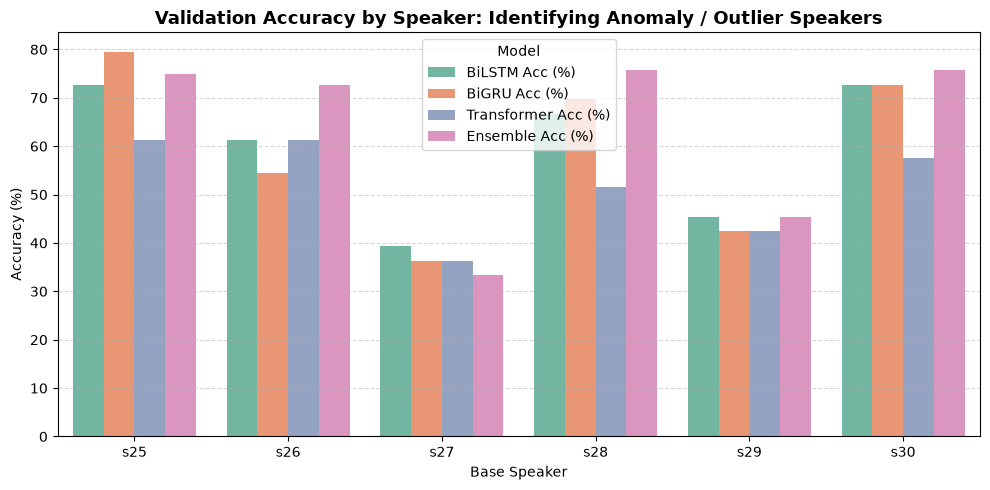

In [7]:
# Section 7: Per-Speaker Accuracy Analysis
speaker_summary = []
for spk in base_val_speakers:
    mask = (df_val["base_speaker"] == spk)
    n_spk = mask.sum()
    speaker_summary.append({
        "Base Speaker": spk,
        "Utterances": n_spk,
        "BiLSTM Acc (%)": round(df_val.loc[mask, "correct_lstm"].mean() * 100, 2),
        "BiGRU Acc (%)": round(df_val.loc[mask, "correct_gru"].mean() * 100, 2),
        "Transformer Acc (%)": round(df_val.loc[mask, "correct_trans"].mean() * 100, 2),
        "Ensemble Acc (%)": round(df_val.loc[mask, "correct_ens"].mean() * 100, 2),
    })

df_speaker_summary = pd.DataFrame(speaker_summary)
print(df_speaker_summary.to_string(index=False))

spk_csv = RESULTS_DIR / "per_speaker_accuracy_breakdown.csv"
df_speaker_summary.to_csv(spk_csv, index=False)
print(f"\nSaved speaker summary table to: {spk_csv}")

# Plot per-speaker comparison barplot
plt.figure(figsize=(10, 5))
bar_df = df_speaker_summary.melt(id_vars=["Base Speaker", "Utterances"], value_vars=["BiLSTM Acc (%)", "BiGRU Acc (%)", "Transformer Acc (%)", "Ensemble Acc (%)"], var_name="Model", value_name="Accuracy")
sns.barplot(data=bar_df, x="Base Speaker", y="Accuracy", hue="Model", palette="Set2")
plt.title("Validation Accuracy by Speaker: Identifying Anomaly / Outlier Speakers", fontsize=13, fontweight="bold")
plt.ylabel("Accuracy (%)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "speaker_accuracy_barplot.png", dpi=200)
plt.show()


## 8. Diagnostic 2: The {d4, d7, d10} Confusion Triangle Breakdown

In [8]:
# Section 8: The {d4, d7, d10} Error Cluster Analysis
target_triangle = [4, 7, 10]
target_names = ["d4", "d7", "d10"]

# Filter manifest for true labels in {d4, d7, d10}
df_triangle = df_val[df_val["digit_id"].isin(target_triangle)].copy()
print(f"Total utterances belonging to {{d4, d7, d10}}: {len(df_triangle)} (Expected ~60 samples)")

# Error in triangle: True in triangle, but predicted incorrectly
df_triangle["err_lstm"] = (~df_triangle["correct_lstm"])
df_triangle["err_gru"] = (~df_triangle["correct_gru"])
df_triangle["err_trans"] = (~df_triangle["correct_trans"])
df_triangle["err_all_three"] = (df_triangle["err_lstm"] & df_triangle["err_gru"] & df_triangle["err_trans"])

# Count errors per speaker inside the triangle
spk_triangle_errors = []
for spk in base_val_speakers:
    m = (df_triangle["base_speaker"] == spk)
    n_total = m.sum()
    err_l = df_triangle.loc[m, "err_lstm"].sum()
    err_g = df_triangle.loc[m, "err_gru"].sum()
    err_t = df_triangle.loc[m, "err_trans"].sum()
    err_all = df_triangle.loc[m, "err_all_three"].sum()
    spk_triangle_errors.append({
        "Speaker": spk,
        "Samples in {d4,d7,d10}": n_total,
        "BiLSTM Errors": f"{err_l}/{n_total} ({err_l/n_total*100:.1f}%)",
        "BiGRU Errors": f"{err_g}/{n_total} ({err_g/n_total*100:.1f}%)",
        "Transformer Errors": f"{err_t}/{n_total} ({err_t/n_total*100:.1f}%)",
        "All 3 Failed": f"{err_all}/{n_total} ({err_all/n_total*100:.1f}%)",
    })

df_spk_err = pd.DataFrame(spk_triangle_errors)
print("\n--- Errors in {d4, d7, d10} Grouped by Speaker ---")
print(df_spk_err.to_string(index=False))
df_spk_err.to_csv(RESULTS_DIR / "d4_d7_d10_errors_by_speaker.csv", index=False)


Total utterances belonging to {d4, d7, d10}: 60 (Expected ~60 samples)

--- Errors in {d4, d7, d10} Grouped by Speaker ---
Speaker  Samples in {d4,d7,d10} BiLSTM Errors BiGRU Errors Transformer Errors All 3 Failed
    s25                      12  8/12 (66.7%) 5/12 (41.7%)       6/12 (50.0%) 4/12 (33.3%)
    s26                      12  5/12 (41.7%) 6/12 (50.0%)       5/12 (41.7%) 4/12 (33.3%)
    s27                       9   6/9 (66.7%)  5/9 (55.6%)        6/9 (66.7%)  5/9 (55.6%)
    s28                       9   3/9 (33.3%)  2/9 (22.2%)        1/9 (11.1%)   0/9 (0.0%)
    s29                       9   5/9 (55.6%)  5/9 (55.6%)        5/9 (55.6%)  4/9 (44.4%)
    s30                       9   3/9 (33.3%)  3/9 (33.3%)        1/9 (11.1%)  1/9 (11.1%)


## 9. Sub-Confusion Matrix for {d4, d7, d10} Across Models

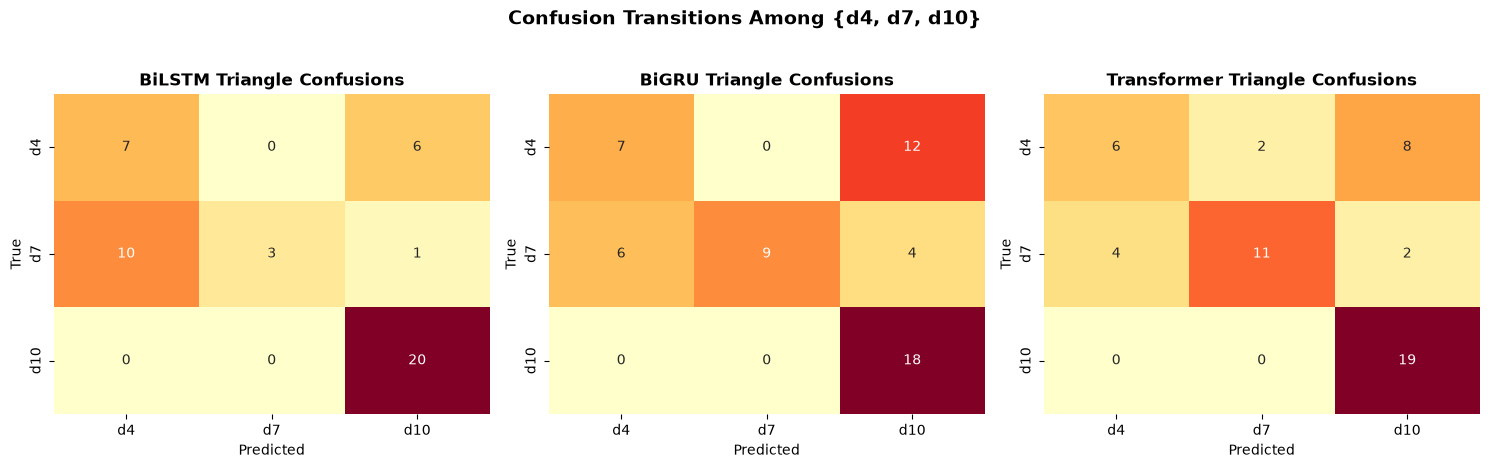

In [9]:
# Section 9: Isolated Confusion Sub-Matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for idx, (m_name, p_col) in enumerate([("BiLSTM", "pred_lstm"), ("BiGRU", "pred_gru"), ("Transformer", "pred_trans")]):
    # Sub-confusion matrix strictly between target classes
    sub_mask = df_val["digit_id"].isin(target_triangle)
    y_true_sub = df_val.loc[sub_mask, "digit_id"]
    y_pred_sub = df_val.loc[sub_mask, p_col]
    
    cm_sub = confusion_matrix(y_true_sub, y_pred_sub, labels=target_triangle)
    sns.heatmap(cm_sub, annot=True, fmt="d", cmap="YlOrRd", xticklabels=target_names, yticklabels=target_names, ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{m_name} Triangle Confusions", fontweight="bold")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("True")

plt.suptitle("Confusion Transitions Among {d4, d7, d10}", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "d4_d7_d10_sub_confusion_matrix.png", dpi=200)
plt.show()


## 10. Listing All Persistent Failure Utterances Across Champions

In [10]:
# Section 10: Specific Misclassified Utterances Where All 3 Models Failed
# Persistent failure in triangle: True class is in {d4, d7, d10} and ALL 3 models misclassified it
persistent_fails = df_val[
    (df_val["digit_id"].isin(target_triangle)) &
    (~df_val["correct_lstm"]) &
    (~df_val["correct_gru"]) &
    (~df_val["correct_trans"])
].copy()

persistent_fails["True_Class"] = persistent_fails["digit_id"].map(ID_TO_CLASS)
persistent_fails["BiLSTM_Pred"] = persistent_fails["pred_lstm"].map(ID_TO_CLASS)
persistent_fails["BiGRU_Pred"] = persistent_fails["pred_gru"].map(ID_TO_CLASS)
persistent_fails["Trans_Pred"] = persistent_fails["pred_trans"].map(ID_TO_CLASS)

summary_cols = ["speaker", "base_speaker", "True_Class", "BiLSTM_Pred", "BiGRU_Pred", "Trans_Pred"]
print(f"Total Persistent Failures in Triangle (Failed by all 3 models): {len(persistent_fails)}")
print(persistent_fails[summary_cols].to_string(index=False))

persistent_csv = RESULTS_DIR / "persistent_triangle_failures.csv"
persistent_fails[summary_cols].to_csv(persistent_csv, index=False)
print(f"Saved persistent failure table to: {persistent_csv}")


Total Persistent Failures in Triangle (Failed by all 3 models): 18
 speaker base_speaker True_Class BiLSTM_Pred BiGRU_Pred Trans_Pred
     s25          s25         d4          d3        d10        d10
s25_aug1          s25         d4         d10        d10        d10
s25_aug2          s25         d4         d10        d10         d3
s25_aug3          s25         d4          d3        d10        d10
     s26          s26         d4          d8        d10         d9
s26_aug1          s26         d4          d8         d8         d7
s26_aug2          s26         d4         d10        d10         d7
s26_aug3          s26         d4          d8        d10         d9
     s27          s27         d7         d10        d10        d10
s27_aug1          s27         d4          d1        d10         d1
s27_aug1          s27         d7          d1        d10         d1
s27_aug2          s27         d4         d10        d10        d10
s27_aug2          s27         d7          d1        d10       

## 11. Visual Inspection: Lip Crop Strip Visualizer for Triangle Errors

Visualizing up to 4 persistent misclassified samples to verify bounding box/cropping quality:


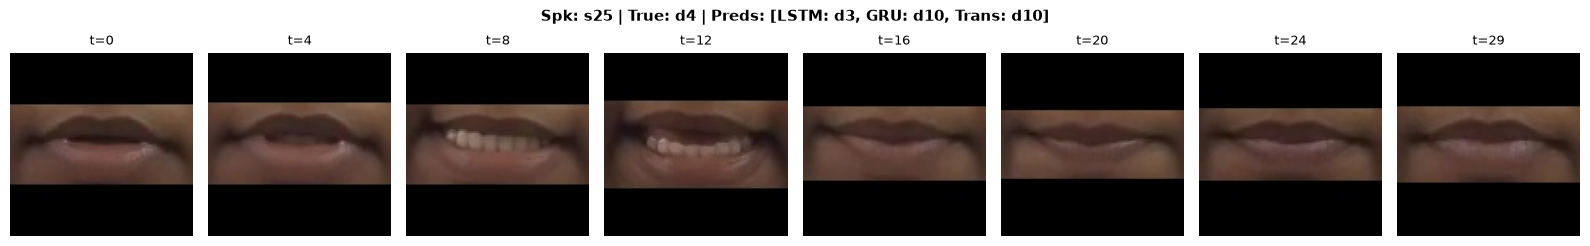

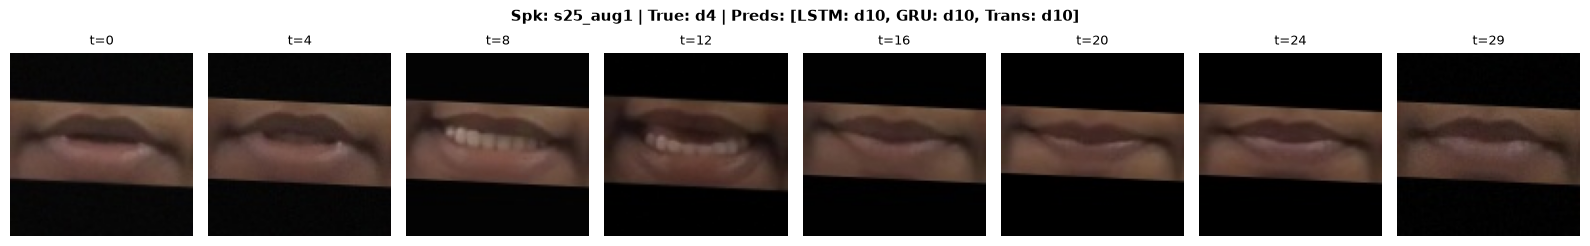

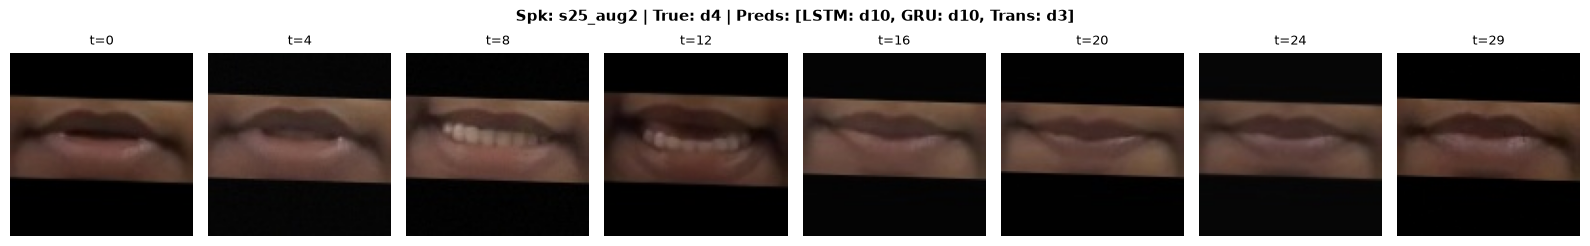

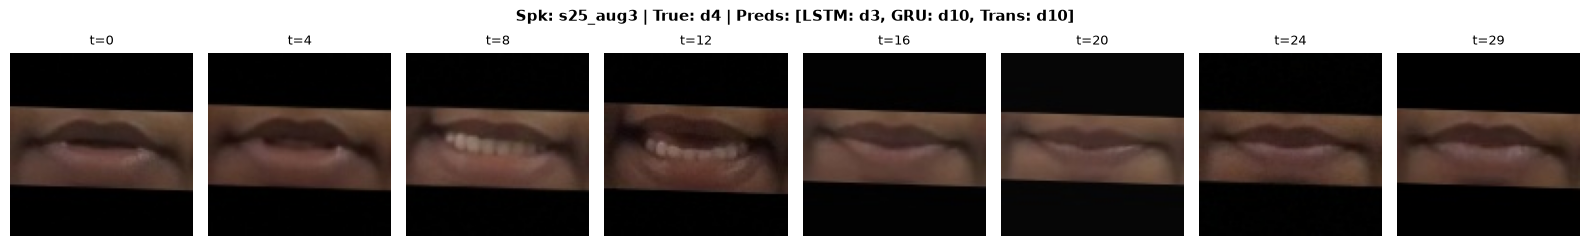

In [11]:
# Section 11: Visualizing Lip Sequence Strips for Persistent Failures
def plot_utterance_strip(row, max_frames=8):
    paths = row["sampled_frame_paths"]
    indices = np.linspace(0, len(paths)-1, max_frames, dtype=int)
    fig, axes = plt.subplots(1, max_frames, figsize=(16, 2.5))
    for idx, f_i in enumerate(indices):
        img = Image.open(paths[f_i])
        axes[idx].imshow(img)
        axes[idx].axis("off")
        axes[idx].set_title(f"t={f_i}", fontsize=9)
    title = f"Spk: {row['speaker']} | True: {row['True_Class']} | Preds: [LSTM: {row['BiLSTM_Pred']}, GRU: {row['BiGRU_Pred']}, Trans: {row['Trans_Pred']}]"
    plt.suptitle(title, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

print("Visualizing up to 4 persistent misclassified samples to verify bounding box/cropping quality:")
for i, (_, row) in enumerate(persistent_fails.head(4).iterrows()):
    plot_utterance_strip(row)


## 12. Diagnostic Conclusions & Actionable Insights

In [12]:
# Section 12: Summary Diagnostics Report
report_text = f"""================================================================================
VALIDATION DIAGNOSTICS & {target_names} TRIANGLE SUMMARY
================================================================================
1. Outlier Speaker Diagnostics:
{df_speaker_summary.to_string(index=False)}

2. {target_names} Cluster Errors by Speaker:
{df_spk_err.to_string(index=False)}

3. Total Persistent Tri-Model Failures in Triangle: {len(persistent_fails)}
Saved all diagnostic CSVs and figures to:
{RESULTS_DIR}
================================================================================
"""
print(report_text)
with open(RESULTS_DIR / "diagnostic_summary_report.txt", "w") as f:
    f.write(report_text)


VALIDATION DIAGNOSTICS & ['d4', 'd7', 'd10'] TRIANGLE SUMMARY
1. Outlier Speaker Diagnostics:
Base Speaker  Utterances  BiLSTM Acc (%)  BiGRU Acc (%)  Transformer Acc (%)  Ensemble Acc (%)
         s25          44           72.73          79.55                61.36             75.00
         s26          44           61.36          54.55                61.36             72.73
         s27          33           39.39          36.36                36.36             33.33
         s28          33           66.67          69.70                51.52             75.76
         s29          33           45.45          42.42                42.42             45.45
         s30          33           72.73          72.73                57.58             75.76

2. ['d4', 'd7', 'd10'] Cluster Errors by Speaker:
Speaker  Samples in {d4,d7,d10} BiLSTM Errors BiGRU Errors Transformer Errors All 3 Failed
    s25                      12  8/12 (66.7%) 5/12 (41.7%)       6/12 (50.0%) 4/12 (33.3%)
    s26 